# Part A — Canny Edge Detection preprocessing pipeline

A classical Canny edge-detection preprocessing pipeline for cervical
colposcopy images. This notebook is a **full rewrite** of the previous
QI-SABP (quantum-inspired) preprocessing notebook: every QI-SABP technique
and configuration item — fused saliency (Sobel / spectral residual /
multi-scale contrast / local entropy / whiteness), glare mask, FOV rim
rules, soft masks, bit maps, adaptive dithered quantisation, YCbCr 4:2:0
chroma subsampling, NLM pre-denoise, bilateral post-filter and partial
histogram matching — has been **REMOVED** and replaced by the single
Canny pipeline below.

## Pipeline overview

* **Step 1 — Unsharp-mask sharpen** (carried over from Step 1; shared with
  the rest of the suite, `amount=0.8`, `ksize=5`).
* **Step 2 — Canny Edge Detection**:
  1. RGB → grayscale.
  2. Gaussian blur 5×5 so Canny does not fire on sensor speckle.
  3. Auto thresholds from the median of the blurred gradient source:
     `low = 0.66 × median`, `high = 1.33 × median` (computed **per image**;
     a fixed-threshold fallback `Canny(low, high)` is available in config).
  4. `cv2.Canny` edge map.
  5. Edge pixels are painted `EDGE_COLOR` (white) back onto the **original**
     image; every non-edge pixel is copied unchanged.

## Output

The pipeline returns the **original image with detected edge pixels
re-coloured** (uint8 RGB, same shape as the input). It is NOT a compression
scheme: no byte stream is produced and the PNG size does not change. The
pipeline is therefore evaluated as an image-processing technique
(distortion, stability, diagnostics), not as a codec.

## What this notebook does NOT claim

* It does NOT produce a compressed byte stream.
* It does NOT compare techniques against each other (that requires the
  multi-patient notebook).
* It does NOT demonstrate a clinical benefit on this single patient.


In [1]:
# ============================================================
# Cell 1.1 — Combined imports & global setup
#   (unused imports removed: scipy.fft, scipy.stats,
#    sklearn.metrics, torch, match_histograms, GridSpec)
# ============================================================
import os, glob, random, warnings, platform

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt

import pandas as pd
from scipy import ndimage
from scipy.ndimage import gaussian_filter

# Part B validator dependencies (hard requirements)
from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Output directory for results / CSV artefacts.
# Relative path so the notebook is portable across Windows / Linux / macOS.
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"\nCanny Edge Detection Validation Pipeline — Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")



Canny Edge Detection Validation Pipeline — Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell 2 -- Configuration
#   Single-class invasive carcinoma dataset.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
#
#   NOTE: this configuration contains ONLY the shared data / Step-1
#   sharpen settings and the Canny pipeline settings. There is no bit
#   budget, no quantisation and no saliency machinery anywhere:
#       Step 1  unsharp-mask sharpen  (carried over from Step 1)
#       Step 2  Canny edge detection  -> edges painted on the original
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
# Use forward slashes -- works on both Windows and Linux/macOS.
DATASET_ROOT   = "C:/CER/dataset"   # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"  # <-- single class folder (note the space)
MASKS_SUBDIR   = "masks"            # set "" if masks live directly under invasive cancer/
CLASSES        = ["invasive cancer"]  # only one class

# ---- Sharpen (Step 1, carried over from the suite) ----
APPLY_SHARPEN  = True
SHARPEN_AMOUNT = 0.8
SHARPEN_KSIZE  = 5

# ---- Canny Edge Detection (Step 2) ----
# The blurred grayscale is thresholded with the classic auto-Canny recipe:
#   low  = CANNY_AUTO_LO_F * median(gray)   (default 0.66 x median)
#   high = CANNY_AUTO_HI_F * median(gray)   (default 1.33 x median)
# computed PER IMAGE, so the pipeline adapts to each frame's exposure.
# Set CANNY_AUTO_THRESH = False to use the fixed CANNY_LOW/CANNY_HIGH pair.
CANNY_AUTO_THRESH  = True    # True = median-based auto thresholds per image
CANNY_AUTO_LO_F    = 0.66    # low  factor (x median)
CANNY_AUTO_HI_F    = 1.33    # high factor (x median)
CANNY_LOW          = 50      # fixed low  (used only when CANNY_AUTO_THRESH = False)
CANNY_HIGH         = 150     # fixed high (used only when CANNY_AUTO_THRESH = False)
CANNY_BLUR_KSIZE   = 5       # Gaussian blur ksize before Canny (odd; 0 disables)
CANNY_APERTURE     = 3       # Sobel aperture size for cv2.Canny
CANNY_L2GRADIENT   = False   # True = more exact L2 gradient magnitude
CANNY_DILATE_ITER  = 0       # optional edge thickening iterations (0 = off)
EDGE_COLOR         = (255, 255, 255)   # RGB colour painted onto edge pixels

# ---- Validation batch (Step 4) ----
SUBSET_PER_CLASS = None      # None = all images

# Global flag set later by the loader -- declared here so all downstream
# cells can reference it without NameError.
SYNTHETIC_MODE = False

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  sharpen={APPLY_SHARPEN} (amount={SHARPEN_AMOUNT}, ksize={SHARPEN_KSIZE})")
print(f"  canny: auto_thresh={CANNY_AUTO_THRESH} "
      f"(lo_f={CANNY_AUTO_LO_F}, hi_f={CANNY_AUTO_HI_F})  "
      f"fixed fallback=({CANNY_LOW}, {CANNY_HIGH})")
print(f"  canny: blur_ksize={CANNY_BLUR_KSIZE}, aperture={CANNY_APERTURE}, "
      f"L2gradient={CANNY_L2GRADIENT}, dilate_iter={CANNY_DILATE_ITER}")
print(f"  edge colour (RGB) = {EDGE_COLOR}")
print(f"  NOTE: no bit budget, no quantisation, no saliency machinery --")
print(f"        non-edge pixels are copied from the input unchanged.")


Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  sharpen=True (amount=0.8, ksize=5)
  canny: auto_thresh=True (lo_f=0.66, hi_f=1.33)  fixed fallback=(50, 150)
  canny: blur_ksize=5, aperture=3, L2gradient=False, dilate_iter=0
  edge colour (RGB) = (255, 255, 255)
  NOTE: no bit budget, no quantisation, no saliency machinery --
        non-edge pixels are copied from the input unchanged.


In [3]:
# ============================================================
# Cell 1.3 -- Sharpen + preprocess + load_dataset
#            (diverse synthetic fallback + SYNTHETIC_MODE flag)
# ============================================================
def sharpen(img_rgb, amount=None, ksize=None):
    """Unsharp-mask sharpening. Applied once after resize."""
    amount = SHARPEN_AMOUNT if amount is None else amount
    ksize  = SHARPEN_KSIZE  if ksize  is None else ksize
    if ksize % 2 == 0:
        ksize += 1                          # cv2.GaussianBlur requires odd ksize
    blurred = cv2.GaussianBlur(img_rgb, (ksize, ksize), 0)
    sharp   = cv2.addWeighted(img_rgb, 1.0 + amount, blurred, -amount, 0)
    return sharp.astype(np.uint8)


def preprocess_image(img_bgr, size=IMG_SIZE, sharpen_it=APPLY_SHARPEN):
    """BGR -> RGB -> resize -> (optional) sharpen. Single source of truth."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    if sharpen_it:
        img = sharpen(img)
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem. Returns (mask, hit_path)
    or (None, None) if no match."""
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 sharpen_it=APPLY_SHARPEN, masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize,
    optionally sharpen. Case-insensitive dedupe by filename so the same
    physical file is never loaded twice on Windows / macOS.

    If a sibling `masks_subdir` folder exists, lesion masks are loaded
    matched by filename stem (e.g. `images/abc.jpg` -> `masks/abc.png`).
    Missing masks default to an all-False mask (H, W) bool and are
    reported. Returns (X, y, paths, masks, n_with_mask, n_dedup).
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size, sharpen_it=sharpen_it)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}  "
              f"| deduped: {n_dup_this}")
        # If a masks/ folder exists but 0 masks matched, warn the user.
        if mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0 and len(files) > 0:
            print(f"    [warn] masks/ folder found at {mask_folder} but 0/{len(files)} "
                  f"images matched. Check that mask filename stems match image stems.")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image AND its lesion mask.

    Returns (image_uint8, mask_bool). The mask is True inside the same
    circles that were drawn into the image, so any saliency-vs-GT
    evaluation has a real target.
    """
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...  (sharpen =", APPLY_SHARPEN, ")")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X_raw, y_raw, paths_raw, masks_raw, n_with_mask, n_dedup = load_out
print(f"\nTotal images : {len(X_raw)} | masks matched: {n_with_mask}/{len(X_raw)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X_raw) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            img = sharpen(img)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y_raw, range(len(y_raw)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw[i] = np.clip(X_raw[i].astype(np.int32) + np.array([dr, dg, db]),
                           0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")


Loading dataset ...  (sharpen = True )
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False


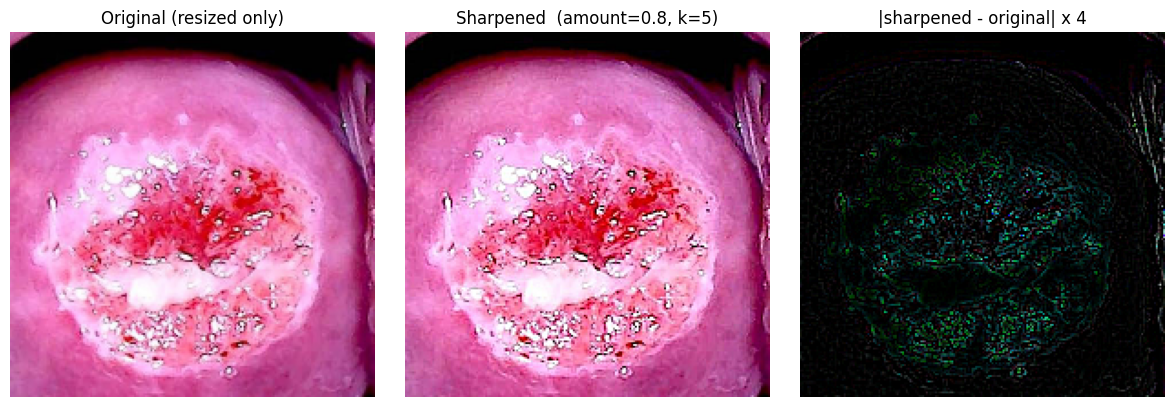

In [4]:
# ============================================================
# Cell 1.4 — Sharpen before/after visualisation (Step 1)
# ============================================================
def show_sharpen_effect(img_path=None, img_rgb=None):
    """Show original / sharpened / high-pass diff for a single image."""
    if img_rgb is None:
        raw_bgr = cv2.imread(img_path)
        if raw_bgr is None:
            print("Could not read", img_path); return
        raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
        raw_resized = cv2.resize(raw_rgb, (IMG_SIZE, IMG_SIZE))
    else:
        raw_resized = img_rgb
    sharpened = sharpen(raw_resized)
    diff = np.clip(sharpened.astype(np.int16) - raw_resized.astype(np.int16),
                   0, 255).astype(np.uint8)

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(raw_resized);    ax[0].set_title("Original (resized only)")
    ax[0].axis("off")
    ax[1].imshow(sharpened);      ax[1].set_title(
        f"Sharpened  (amount={SHARPEN_AMOUNT}, k={SHARPEN_KSIZE})")
    ax[1].axis("off")
    ax[2].imshow(diff * 4, cmap="gray")  # x4 to make the high-pass visible
    ax[2].set_title("|sharpened - original| x 4")
    ax[2].axis("off")
    plt.tight_layout(); plt.show()


if len(X_raw) > 0:
    # X_raw is already sharpened -- rebuild the un-sharpened version for
    # the left panel so the comparison is honest.
    if not SYNTHETIC_MODE:
        _before = preprocess_image(cv2.imread(paths_raw[0]), size=IMG_SIZE,
                                   sharpen_it=False)
    else:
        _img0, _ = make_synthetic_image_and_mask(seed=SEED)
        _before = np.clip(_img0.astype(np.int32)
                          + np.array(class_color_offset.get(y_raw[0], (0, 0, 0))),
                          0, 255).astype(np.uint8)
    show_sharpen_effect(img_rgb=_before)
else:
    demo = np.random.RandomState(SEED).randint(40, 200, (200, 200, 3), dtype=np.uint8)
    demo[60:140, 60:140] = np.random.RandomState(SEED+1).randint(160, 255, (80, 80, 3), dtype=np.uint8)
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(demo);               ax[0].set_title("Original");       ax[0].axis("off")
    ax[1].imshow(sharpen(demo));      ax[1].set_title("Sharpened");      ax[1].axis("off")
    plt.tight_layout(); plt.show()


In [5]:
# ============================================================
# Cell 2.1 -- Canny Edge Detection preprocessing pipeline
#   gray -> Gaussian blur -> auto-median thresholds -> cv2.Canny
#        -> edge pixels painted EDGE_COLOR onto the ORIGINAL image
#   (no bit budget, no quantiser; non-edge pixels are copied unchanged)
# ============================================================

def auto_canny_thresholds(gray, lo_f=None, hi_f=None):
    """Median-based auto-Canny thresholds (per image).

    low  = CANNY_AUTO_LO_F * median(gray)   (default 0.66 x median)
    high = CANNY_AUTO_HI_F * median(gray)   (default 1.33 x median)

    The classic auto-Canny heuristic: the median is a robust exposure
    estimate, so the thresholds follow the frame's brightness instead of
    being hard-coded. Returns (low, high) as ints clipped to [0, 255],
    with low >= 1 and high > low so Canny is always well-defined.
    """
    lo_f = CANNY_AUTO_LO_F if lo_f is None else lo_f
    hi_f = CANNY_AUTO_HI_F if hi_f is None else hi_f
    med = float(np.median(gray))
    lo = int(np.clip(round(lo_f * med), 0, 255))
    hi = int(np.clip(round(hi_f * med), 0, 255))
    lo = max(lo, 1)          # avoid a degenerate 0 threshold on dark frames
    hi = max(hi, lo + 1)     # high must exceed low
    return lo, hi


def canny_edge_map(img_rgb, blur_ksize=None, auto_thresh=None, low=None,
                   high=None, aperture=None, l2_gradient=None, dilate_iter=None):
    """Compute the Canny edge binary map for an RGB uint8 image.

    Returns (edges_uint8 {0,1}, meta) where meta carries the thresholds
    actually used (provenance for the validation tables).
    """
    blur_ksize   = CANNY_BLUR_KSIZE   if blur_ksize   is None else blur_ksize
    auto_thresh  = CANNY_AUTO_THRESH  if auto_thresh  is None else auto_thresh
    low          = CANNY_LOW          if low          is None else low
    high         = CANNY_HIGH         if high         is None else high
    aperture     = CANNY_APERTURE     if aperture     is None else aperture
    l2_gradient  = CANNY_L2GRADIENT   if l2_gradient  is None else l2_gradient
    dilate_iter  = CANNY_DILATE_ITER  if dilate_iter  is None else dilate_iter

    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    if blur_ksize and blur_ksize >= 3:
        k = blur_ksize if blur_ksize % 2 == 1 else blur_ksize + 1
        gray_blur = cv2.GaussianBlur(gray, (k, k), 0)
    else:
        k = 0
        gray_blur = gray
    if auto_thresh:
        lo, hi = auto_canny_thresholds(gray_blur)
    else:
        lo, hi = int(low), int(high)
        lo = max(lo, 1)
        hi = max(hi, lo + 1)
    edges = cv2.Canny(gray_blur, lo, hi, apertureSize=aperture,
                      L2gradient=l2_gradient)
    if dilate_iter and dilate_iter > 0:
        kernel = np.ones((3, 3), np.uint8)
        edges = cv2.dilate(edges, kernel, iterations=int(dilate_iter))
    meta = dict(canny_lo=lo, canny_hi=hi, blur_ksize=k,
                aperture=aperture, l2_gradient=l2_gradient)
    return (edges > 0).astype(np.uint8), meta


def canny_preprocess(img_rgb, return_artefacts=True):
    """Canny Edge Detection preprocessing. Fully deterministic.

    Output = the ORIGINAL image with detected edge pixels painted
    EDGE_COLOR; every non-edge pixel is copied unchanged. There is no
    bit budget and no quantisation anywhere in this pipeline.
    """
    edges, meta = canny_edge_map(img_rgb)
    out = np.asarray(img_rgb, dtype=np.uint8).copy()
    out[edges > 0] = np.array(EDGE_COLOR, dtype=np.uint8)
    if return_artefacts:
        return dict(processed=out,
                    edges=edges,
                    canny_lo=meta["canny_lo"], canny_hi=meta["canny_hi"],
                    blur_ksize=meta["blur_ksize"],
                    edge_density=float(edges.mean()))
    return out


# Quick smoke test on the first image
_sm = canny_preprocess(X_raw[0], return_artefacts=True)
assert _sm["processed"].shape == X_raw[0].shape and _sm["processed"].dtype == np.uint8
print(f"canny_preprocess ready  |  smoke test on X_raw[0]: "
      f"out shape={_sm['processed'].shape} dtype={_sm['processed'].dtype}  "
      f"thresholds=({_sm['canny_lo']}, {_sm['canny_hi']})  "
      f"edge_density={_sm['edge_density']:.4f}  "
      f"mean|diff|={np.abs(_sm['processed'].astype(int) - X_raw[0].astype(int)).mean():.3f}")


canny_preprocess ready  |  smoke test on X_raw[0]: out shape=(200, 200, 3) dtype=uint8  thresholds=(98, 198)  edge_density=0.0796  mean|diff|=7.016


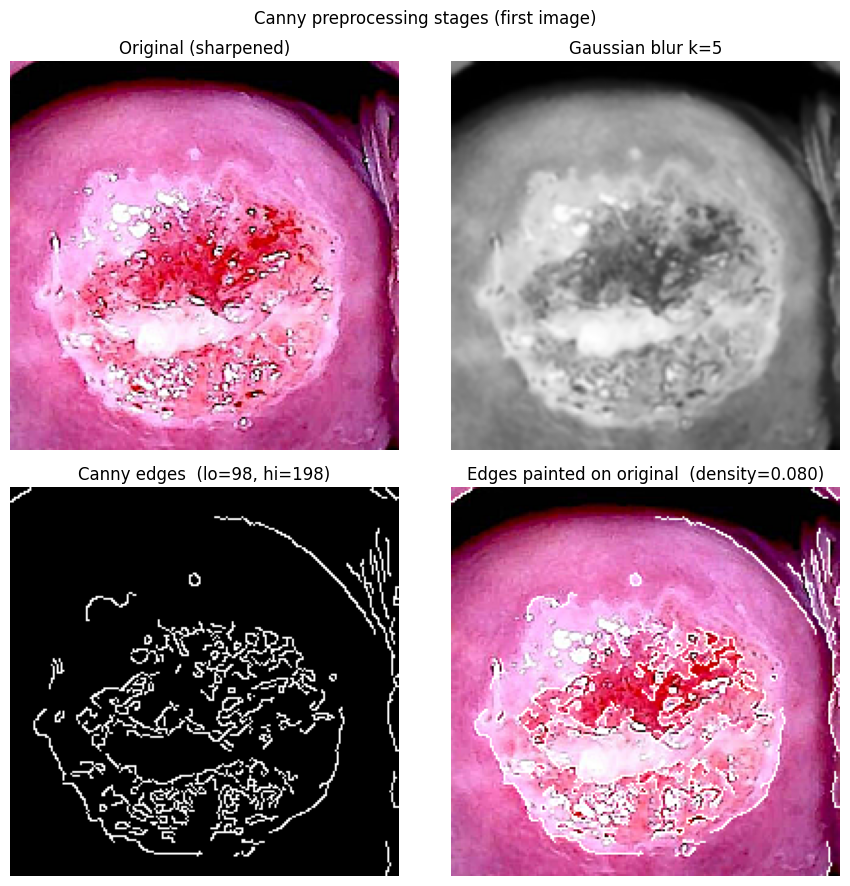

Edge density over 128 images: mean=0.0820  min=0.0785  max=0.0872  std=0.0023
  (3280 edge px per 200x200 frame on average)


In [6]:
# ============================================================
# Cell 2.2 -- Canny stage visualisation + edge density summary
# ============================================================
def show_canny_stages(img_rgb, title=""):
    """Show original / blurred gray / edge map / edges-on-original."""
    art = canny_preprocess(img_rgb, return_artefacts=True)
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    if art["blur_ksize"] and art["blur_ksize"] >= 3:
        gray_blur = cv2.GaussianBlur(gray, (art["blur_ksize"], art["blur_ksize"]), 0)
    else:
        gray_blur = gray

    fig, ax = plt.subplots(2, 2, figsize=(9, 9))
    ax[0, 0].imshow(img_rgb); ax[0, 0].set_title("Original (sharpened)")
    ax[0, 1].imshow(gray_blur, cmap="gray")
    ax[0, 1].set_title(f"Gaussian blur k={art['blur_ksize']}")
    ax[1, 0].imshow(art["edges"], cmap="gray")
    ax[1, 0].set_title(f"Canny edges  (lo={art['canny_lo']}, hi={art['canny_hi']})")
    ax[1, 1].imshow(art["processed"])
    ax[1, 1].set_title(f"Edges painted on original  (density={art['edge_density']:.3f})")
    for a in ax.ravel():
        a.axis("off")
    if title:
        fig.suptitle(title)
    plt.tight_layout(); plt.show()


# --- Stage figure for the first image ---
if len(X_raw) > 0:
    show_canny_stages(X_raw[0], title="Canny preprocessing stages (first image)")

# --- Edge density across the whole stack (fast; Canny is cheap) ---
if len(X_raw) > 0:
    densities = np.array([canny_edge_map(im)[0].mean() for im in X_raw])
    print(f"Edge density over {len(densities)} images: "
          f"mean={densities.mean():.4f}  min={densities.min():.4f}  "
          f"max={densities.max():.4f}  std={densities.std():.4f}")
    print(f"  ({int(round(densities.mean() * IMG_SIZE * IMG_SIZE))} edge px per "
          f"{IMG_SIZE}x{IMG_SIZE} frame on average)")


# Bridge — hand off Canny preprocessing to Step 4

Step 4 expects five variables from Steps 1–2:

| Step-4 name | Meaning                                   | Source in this notebook                 |
|-------------|-------------------------------------------|----------------------------------------|
| `X_base`    | (N,200,200,3) uint8 RGB, **sharpened**    | loader's `X_raw` (sharpened by loader) |
| `X_raw`     | (N,200,200,3) uint8 RGB, **resize-only**  | reloaded with `sharpen_it=False`       |
| `image_ids` | unique id per image                       | sequential `img_NNNN`                  |
| `masks`     | clinician lesion masks (OPTIONAL)         | `masks_raw` from the loader            |
| `patient`   | patient id (OPTIONAL)                     | `None`                                 |

We register the technique:

* `CANNY_DEFAULTS` — empty dict (the pipeline uses fixed module-level config; **no tuning on a single patient**).
* `canny_edge(img, params, seed) -> uint8 RGB image` — wraps `canny_preprocess(img, return_artefacts=False)`.
  Determinism: `cv2.Canny` is fully deterministic, so the per-image seed is accepted for API compatibility only (the QI-SABP pipeline needed it for its dither RNG; Canny does not).


In [7]:
# ============================================================
# Bridge -- hand off Canny preprocessing to Step 4.
# ============================================================

# --- Step-2 sharpened stack becomes the validator's X_base ---
X_base = X_raw.copy()                       # sharpened, 200x200, uint8 RGB
_masks = masks_raw.copy()                   # clinician masks (synthetic in fallback)

# --- Unique image ids (always sequential -> guaranteed unique) ---
image_ids = np.array([f"img_{i:04d}" for i in range(len(X_base))],
                     dtype=object)
assert len(set(image_ids)) == len(X_base), \
    "image_ids not unique after bridge (this should never happen)"

# --- Reload the SAME images WITHOUT sharpening -> validator's X_raw ---
#     (used only as the source for the field-of-view mask)
if not SYNTHETIC_MODE:
    _X_unsharp, _y_unsharp, _paths_unsharp, _masks_unsharp, _n_wm, _n_dd = load_dataset(
        DATASET_ROOT, CLASSES,
        size=IMG_SIZE,
        subset_per_class=SUBSET_PER_CLASS,
        sharpen_it=False,                  # <-- resize-only
    )
    if len(_X_unsharp) == 0:               # safety net: fall back to sharpened
        X_raw_unsharp = X_base.copy()
    else:
        X_raw_unsharp = _X_unsharp
        if len(X_raw_unsharp) != len(X_base):
            print(f"[bridge] X_raw_unsharp count ({len(X_raw_unsharp)}) != "
                  f"X_base count ({len(X_base)}); falling back to X_base.")
            X_raw_unsharp = X_base.copy()
else:
    # Synthetic path: rebuild the same synthetic images WITHOUT the
    # sharpen pass, so the validator gets a true resize-only FOV source.
    _xs = []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, _ = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            _xs.append(img)
    X_raw_unsharp = np.stack(_xs).astype(np.uint8)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw_unsharp[i] = np.clip(
            X_raw_unsharp[i].astype(np.int32) + np.array([dr, dg, db]),
            0, 255,
        ).astype(np.uint8)

# Step 4 expects the name `X_raw` for the resize-only stack.
X_raw = X_raw_unsharp

# Final shape assertions
assert X_base.dtype == np.uint8 and X_base.ndim == 4 and X_base.shape[-1] == 3, \
    f"X_base must be (N,H,W,3) uint8, got {X_base.shape} {X_base.dtype}"
assert X_raw.shape == X_base.shape, \
    f"X_raw {X_raw.shape} != X_base {X_base.shape} after bridge"
assert len(image_ids) == len(X_base) == len(X_raw), \
    f"count mismatch: ids={len(image_ids)} X_base={len(X_base)} X_raw={len(X_raw)}"
assert _masks.shape == (len(X_base), IMG_SIZE, IMG_SIZE), \
    f"masks shape {_masks.shape} != ({len(X_base)}, {IMG_SIZE}, {IMG_SIZE})"

masks = _masks   # pass-through to Step 4 (None-safe inside make_cache)
print(f"Bridge ready | X_base (sharpened) = {X_base.shape} {X_base.dtype} | "
      f"X_raw (resize-only) = {X_raw.shape} {X_raw.dtype} | "
      f"image_ids = {len(image_ids)} (all unique) | masks = {masks.shape} "
      f"({int(masks.any((1,2)).sum())}/{len(masks)} have a lesion) | "
      f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")

# ---- Canny wrapper for Step 4 -----------------------------------------
CANNY_DEFAULTS = {}

def canny_edge(img, params=None, seed=0):
    """Canny Edge Detection preprocessing, exposed to the Step 4 validator.

    Signature: canny_edge(img_uint8_RGB, params_dict, seed) -> uint8 RGB image.
    `params` and `seed` are accepted for API compatibility but ignored
    (the pipeline uses fixed module-level configuration and cv2.Canny is
    fully deterministic; no tuning on a single patient).
    """
    return canny_preprocess(img, return_artefacts=False)

# Quick smoke test on the first image
_sm = canny_edge(X_base[0], CANNY_DEFAULTS, seed=12345)
assert _sm.shape == X_base[0].shape and _sm.dtype == np.uint8, \
    f"canny_edge smoke test failed: got {_sm.shape} {_sm.dtype}"
assert np.array_equal(canny_edge(X_base[0], CANNY_DEFAULTS, seed=12345), _sm), \
    "canny_edge is not deterministic for the same seed"
print(f"canny_edge() wrapper ready  |  CANNY_DEFAULTS = {CANNY_DEFAULTS}  |  "
      f"smoke test on X_base[0]: out shape={_sm.shape} dtype={_sm.dtype}  "
      f"mean|diff|={np.abs(_sm.astype(int)-X_base[0].astype(int)).mean():.3f}")


       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0
Bridge ready | X_base (sharpened) = (128, 200, 200, 3) uint8 | X_raw (resize-only) = (128, 200, 200, 3) uint8 | image_ids = 128 (all unique) | masks = (128, 200, 200) (0/128 have a lesion) | SYNTHETIC_MODE = False
canny_edge() wrapper ready  |  CANNY_DEFAULTS = {}  |  smoke test on X_base[0]: out shape=(200, 200, 3) dtype=uint8  mean|diff|=7.016


# Part B — Step 4 rewrite: table-only validation with 11 metrics

Single-patient, N distinct clusters (dHash). The frames are NOT
independent. Descriptive only — no p-values, no robustness or population
claims.

**Technique:** `CannyEdge` — Canny edge detection preprocessing
(Gaussian 5×5 → auto-median thresholds → edges painted on the original).

**Metrics — exactly 11**, in 5 groups (fidelity, colour, diagnostic
structure, quality, cost). All computed inside the FOV mask only, per
image, against the ORIGINAL image:

| # | Metric | Group | Better |
|---|--------|-------|--------|
| m1  | PSNR (dB)             | fidelity  | up |
| m2  | SSIM                  | fidelity  | up |
| m3  | CIE76 ΔE              | colour    | down |
| m4  | a* correlation        | colour    | up |
| m5  | \|mean a* shift\|     | colour    | down |
| m6  | Vessel Dice           | structure | up |
| m7  | Edge IoU              | structure | up |
| m8  | Sharpness ratio       | quality   | neutral |
| m9  | Noise ratio           | quality   | down |
| m10 | Saturation ratio      | quality   | neutral |
| m11 | Luma bits (entropy)   | cost      | info |

**Luma bits** is defined as the Shannon entropy of the PROCESSED luma
histogram (256 bins) inside the FOV, in bits/px (max 8.0). This replaces
the old QI-SABP analytic bit-budget: Canny does not quantise, so the only
honest "bits" quantity left is the information content of the output.

**Tables only.** No figures, no plots. T1 (main), T5 (per cluster),
T7 (paired CIs), T6 (caveats). The QI-SABP-specific tables (T4 ablation,
T8 region-split, inside/outside-hard-mask split) are REMOVED — there is no
mask in this pipeline.

`cache_hash` is printed for provenance only (no assert — Part A is no
longer frozen; the expected value on the unchanged dataset + Step-1
sharpen is still `12f68b681210`).


In [8]:
# ============================================================
# Step 4.1 -- Freeze inputs: cache_hash (provenance), FOV masks,
#              dHash cluster ids.
# ============================================================
import hashlib as _hashlib
from scipy import ndimage

# ---- FOV + cluster helpers (identical to the previous validator) ----
def _dhash_step4(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

def _compute_fov_step4(img_rgb, thr=15):
    """FOV mask: largest bright connected region, holes filled, convex-hull
    notch fill, 11x11 ellipse close (same as before)."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    # Convex-hull fill (fills black frame triangles / zigzag teeth)
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1+1, x0:x1+1] = True
        hull_mask = hull_mask & bbox
        ksize = 11
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                      cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov

# ---- Build the cache from X_base (the sharpened stack) ----
images = X_base       # (N, 200, 200, 3) uint8 RGB, sharpened
images_raw = X_raw    # (N, 200, 200, 3) uint8 RGB, resize-only (for FOV)
n_images = len(images)
image_id = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)
fov = np.stack([_compute_fov_step4(images_raw[i]) for i in range(n_images)])

# dHash clustering (frames from one video stream are near-duplicates)
hs = [_dhash_step4(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)) for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    if cluster_ids[i] >= 0:
        continue
    cluster_ids[i] = _next
    for j in range(i + 1, n_images):
        if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
            cluster_ids[j] = _next
    _next += 1
n_clusters = len(np.unique(cluster_ids))
cluster_reps = np.array([np.where(cluster_ids == uc)[0][0]
                          for uc in np.unique(cluster_ids)], dtype=int)

# ---- cache_hash (PROVENANCE ONLY -- no assert) ----
# With the dataset and the Step-1 sharpen unchanged this must be
# 12f68b681210; if it differs, the input changed (different data,
# different IMG_SIZE or sharpen), which is legitimate for this rewrite.
_h = _hashlib.md5("|".join(map(str, image_id)).encode())
_h.update(np.ascontiguousarray(images).tobytes())
cache_hash = _h.hexdigest()[:12]
print(f"cache_hash = {cache_hash}  "
      f"(expected 12f68b681210 on the unchanged dataset + Step-1 sharpen)")
print(f"  n_images = {n_images} | n_clusters (dHash) = {n_clusters} | "
      f"n_distinct = {len(cluster_reps)}")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters "
      f"from one patient). All tables say this.")


cache_hash = 12f68b681210  (expected 12f68b681210 on the unchanged dataset + Step-1 sharpen)
  n_images = 128 | n_clusters (dHash) = 7 | n_distinct = 7
  The 128 frames are NOT independent (7 distinct clusters from one patient). All tables say this.


In [9]:
# ============================================================
# Step 4.2 -- step4_validator + helper functions.
#              Computes EXACTLY 11 metrics inside the FOV only.
# ============================================================

def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    try:
        from skimage.filters import frangi
        v = frangi(gray, black_ridges=False)
        v = v / (v.max() + 1e-8)
    except Exception:
        # Fallback: Sobel-based ridge detection
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    return v.astype(np.float32)

def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV.
    Binarizes each vessel map at the (100 - top_pct) percentile inside
    the FOV, then computes Dice = 2*|A∩B| / (|A| + |B|)."""
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    denom = float(b_o.sum()) + float(b_p.sum())
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom

def _edge_map(img_rgb):
    """Validator's own Canny edge binary map (fixed 50/150 -- independent
    of the preprocessing's threshold choice)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)

def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])

def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)

def _specular_mask(img_rgb):
    """Specular/saturated pixel mask (V >= 250 AND S <= 25 in HSV)."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)

def _luma_entropy(gray, mask):
    """Shannon entropy of the luma histogram (256 bins) inside the mask,
    in bits/px. Max 8.0 for 8-bit luma."""
    v = np.asarray(gray)[mask]
    if v.size == 0:
        return float('nan')
    counts = np.bincount(v.ravel(), minlength=256).astype(np.float64)
    p = counts / counts.sum()
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def step4_validator(original, processed, fov_mask):
    """Compute the 11 validation metrics inside the FOV only, per image.

    Returns a dict with keys m1..m11:
      m1  PSNR (dB)                    up
      m2  SSIM                         up
      m3  CIE76 dE                     down
      m4  a* correlation               up
      m5  |mean a* shift|              down
      m6  Vessel Dice (top 10% Frangi) up
      m7  Edge IoU                     up
      m8  Sharpness ratio (out/in)     neutral (0.9-1.1)
      m9  Noise ratio (out/in)         down
      m10 Saturation ratio (out/in)    neutral (at most 1)
      m11 Luma bits (entropy of the PROCESSED luma inside FOV, bits/px, max 8.0)
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)
    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    # m2: SSIM (FOV-masked)
    ssim_map = _ssim_fn(original, processed, channel_axis=2,
                         full=True, data_range=255)[1]
    m2 = float(ssim_map.mean(2)[f].mean())
    # m3: CIE76 dE (stating which: CIE76)
    m3 = float(_deltaE_fn(_rgb2lab_fn(original), _rgb2lab_fn(processed))[f].mean())
    # m4: a* correlation
    lab_o = _rgb2lab_fn(original)
    lab_p = _rgb2lab_fn(processed)
    m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
    # m5: |mean a* shift|
    a_o = float(lab_o[..., 1][f].mean())
    a_p = float(lab_p[..., 1][f].mean())
    m5 = abs(a_p - a_o)
    # m6: Vessel Dice (top 10% Frangi pixels)
    m6 = _vessel_dice(original, processed, f, top_pct=10)
    # m7: Edge IoU
    e_o = _edge_map(original)
    e_p = _edge_map(processed)
    m7 = _edge_iou(e_o, e_p, f)
    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)
    # m9: Noise ratio (out/in) -- 1.4826 * MAD of high-pass, smooth regions
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                   cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')
    # m10: Saturation ratio (output saturated / input saturated).
    # Measures NEW saturated pixels introduced by the technique; > 1 means
    # the technique adds saturated pixels. The denominator is floored at
    # 1 PIXEL (not 1e-9) so the ratio stays finite and interpretable when
    # the input contains no saturated pixels at all (e.g. painting white
    # edges creates saturated pixels from a zero base).
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    m10 = float(sp_p[f].sum()) / max(float(sp_o[f].sum()), 1.0)
    # m11: Luma bits (entropy of the PROCESSED luma histogram inside FOV)
    m11 = _luma_entropy(cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY), f)
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10, m11=m11)

# Metric metadata (key, name, group, better direction)
METRIC_META = [
    ("m1",  "PSNR (dB)",             "fidelity",  "up"),
    ("m2",  "SSIM",                  "fidelity",  "up"),
    ("m3",  "CIE76 dE",              "colour",    "down"),
    ("m4",  "a* corr",               "colour",    "up"),
    ("m5",  "|a* shift|",            "colour",    "down"),
    ("m6",  "Vessel Dice",           "structure", "up"),
    ("m7",  "Edge IoU",              "structure", "up"),
    ("m8",  "Sharpness ratio",       "quality",   "neutral"),
    ("m9",  "Noise ratio",           "quality",   "down"),
    ("m10", "Saturation ratio",      "quality",   "neutral"),
    ("m11", "Luma bits (entropy)",   "cost",      "info"),
]
METRIC_KEYS = [m[0] for m in METRIC_META]
METRIC_NAMES = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
print("step4_validator ready: EXACTLY 11 metrics (m1..m11).")
print("  Removed from the old metric set: Time per image (old m12).")
print("  m11: Luma bits = luma entropy (information content of the output).")


step4_validator ready: EXACTLY 11 metrics (m1..m11).
  Removed from the old metric set: Time per image (old m12).
  m11: Luma bits = luma entropy (information content of the output).


In [10]:
# ============================================================
# Step 4.3 -- Compute the 11 metrics for CannyEdge. Write per-image CSV.
#              Also cache processed images (no re-runs downstream).
# ============================================================
for _old in glob.glob(os.path.join(SAVE_DIR, "results_*.csv")):
    os.remove(_old)
    print(f"  Deleted stale {_old}")

TECHNIQUE = "CannyEdge"
processed_cache = {}   # (technique, image_idx) -> uint8 RGB

rows = []
for i in range(n_images):
    orig = images[i]
    fov_i = fov[i]
    proc = canny_edge(orig, CANNY_DEFAULTS, seed=42 + i)
    m = step4_validator(orig, proc, fov_i)
    m["technique"] = TECHNIQUE
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows.append(m)
    processed_cache[(TECHNIQUE, i)] = proc.copy()
    if (i + 1) % 20 == 0 or i == n_images - 1:
        print(f"  processed {i + 1}/{n_images} images...")

df_canny = pd.DataFrame(rows)
_csv_out = os.path.join(SAVE_DIR, f"results_{TECHNIQUE}.csv")
df_canny.to_csv(_csv_out, index=False)
print(f"Wrote {_csv_out} ({len(df_canny)} rows)")
print(f"  Mean luma bits (entropy) = {df_canny['m11'].mean():.3f}")
print(f"  Mean PSNR = {df_canny['m1'].mean():.2f} dB | "
      f"Mean dE76 = {df_canny['m3'].mean():.3f} | "
      f"Mean Edge IoU = {df_canny['m7'].mean():.3f}")


  processed 20/128 images...
  processed 40/128 images...
  processed 60/128 images...
  processed 80/128 images...
  processed 100/128 images...
  processed 120/128 images...
  processed 128/128 images...
Wrote results\results_CannyEdge.csv (128 rows)
  Mean luma bits (entropy) = 7.378
  Mean PSNR = 17.94 dB | Mean dE76 = 4.735 | Mean Edge IoU = 0.654


In [11]:
# ============================================================
# Step 4.4 -- Reference row: Identity (the untouched sharpened frame).
#              Mask-variant baselines and ablation rows from the old
#              bit-allocation pipeline are not applicable here (no bit
#              allocation exists) and are not run.
# ============================================================
rows_id = []
for i in range(n_images):
    processed_cache[("Identity", i)] = images[i].copy()
    m = step4_validator(images[i], images[i], fov[i])
    m["technique"] = "Identity"
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows_id.append(m)
df_id = pd.DataFrame(rows_id)
_csv_out = os.path.join(SAVE_DIR, "results_Identity.csv")
df_id.to_csv(_csv_out, index=False)
print(f"Wrote {_csv_out} ({len(df_id)} rows)")
print("  Identity is a reference row only: PSNR ~148 dB (epsilon-floor "
      "artefact of zero MSE), dE=0, Dice=1.0, IoU=1.0 are ideal values.")


Wrote results\results_Identity.csv (128 rows)
  Identity is a reference row only: PSNR ~148 dB (epsilon-floor artefact of zero MSE), dE=0, Dice=1.0, IoU=1.0 are ideal values.


In [12]:
# ============================================================
# Step 4.5 -- Merge cell: concatenate the technique CSVs. Assert each
#              technique has n_images rows and the same cluster ids.
#              Assert no NaNs in any metric column.
#              Uses a FIXED list of CSV names (not glob) to prevent
#              stale files from earlier runs leaking into the tables.
# ============================================================
_csv_names = [
    "results_CannyEdge.csv",
    "results_Identity.csv",
]
print(f"Reading {len(_csv_names)} CSV files (fixed list, not glob)")
dfs = []
for _f in _csv_names:
    _path = os.path.join(SAVE_DIR, _f)
    _df = pd.read_csv(_path)
    _tech = _df["technique"].iloc[0] if len(_df) > 0 else _f
    assert len(_df) == n_images, f"{_f} has {len(_df)} rows, expected {n_images}"
    assert list(_df["cluster_id"]) == list(cluster_ids), f"{_f} cluster ids differ"
    dfs.append(_df)
    print(f"  {_f}: {len(_df)} rows, technique = {_tech}")

merged = pd.concat(dfs, ignore_index=True)
print(f"Merged: {len(merged)} rows, {merged['technique'].nunique()} techniques")

# Hard assert: no NaN in any metric column.
_nan_cols = {}
for col in METRIC_KEYS:
    n_nan = merged[col].isna().sum()
    if n_nan > 0:
        _nan_cols[col] = int(n_nan)
assert len(_nan_cols) == 0, (
    f"NaN values found: {_nan_cols}. Every metric must be computable "
    f"inside the FOV for every image.")
print("No NaN values in any metric column.")

techniques = sorted(merged["technique"].unique())
print(f"Techniques: {techniques}")


Reading 2 CSV files (fixed list, not glob)
  results_CannyEdge.csv: 128 rows, technique = CannyEdge
  results_Identity.csv: 128 rows, technique = Identity
Merged: 256 rows, 2 techniques
No NaN values in any metric column.
Techniques: ['CannyEdge', 'Identity']


In [13]:
# ============================================================
# Step 4.6 -- Aggregation: average within each cluster first, then
#              across clusters. 95% CI from a cluster bootstrap
#              (n_clusters clusters, 2000 resamples, fixed seed).
#              Label: "within-patient, NOT a population CI".
# ============================================================

def _cluster_mean(tech_df, metric_key):
    """Average within each cluster first, then across clusters."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())

def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=2000, seed=42):
    """Bootstrap CI over clusters (2000 resamples).
    Returns (mean, ci_lo, ci_hi). WITHIN-PATIENT, NOT a population CI."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))

# Compute the cluster-weighted mean and CI for each technique x metric.
agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean, lo, hi = _cluster_bootstrap_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")
print("Aggregation done (cluster-weighted mean + 95% CI).")
print(f"  WITHIN-PATIENT, {n_clusters} clusters, NOT a population CI.")


Aggregation done (cluster-weighted mean + 95% CI).
  WITHIN-PATIENT, 7 clusters, NOT a population CI.


In [14]:
# ============================================================
# Step 4.7 -- Statistics: CannyEdge vs Identity, per key metric.
#              Uses paired difference per cluster + bootstrap CI.
#              Reports "CI excludes 0: yes/no".
#              Descriptive, no significance claim.
# ============================================================

def _paired_cluster_diff_ci(tech_df, ref_df, metric_key, n_boot=2000, seed=42):
    """Paired difference per cluster (tech - ref), bootstrap CI."""
    tech_cm = tech_df.groupby("cluster_id")[metric_key].mean()
    ref_cm = ref_df.groupby("cluster_id")[metric_key].mean()
    diff = (tech_cm - ref_cm).values
    if len(diff) < 2:
        return float('nan'), float('nan'), float('nan'), False
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(diff), size=len(diff))
        boots.append(diff[idx].mean())
    boots = np.array(boots)
    lo, hi = float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))
    excludes = (lo > 0) or (hi < 0)
    return float(diff.mean()), lo, hi, excludes

# Key metrics for the paired comparison vs Identity (skip PSNR / SSIM /
# luma bits -- they are meaningless against Identity: ~-138 dB, dE=0).
key_metrics = ["m3", "m5", "m6", "m7", "m9"]
stat_rows = []
canny_df = merged[merged["technique"] == "CannyEdge"]
id_df = merged[merged["technique"] == "Identity"]
for mk in key_metrics:
    md, lo, hi, ex = _paired_cluster_diff_ci(canny_df, id_df, mk)
    stat_rows.append({
        "metric": METRIC_NAMES[mk], "comparison": "CannyEdge vs Identity",
        "mean_diff": md, "ci_lo": lo, "ci_hi": hi,
        "CI_excludes_0": "yes" if ex else "no",
    })
stat_df = pd.DataFrame(stat_rows)
print("Statistics done. CannyEdge vs Identity, key metrics only.")
print("  Descriptive, no significance claim. "
      f"{n_clusters} clusters, within-patient.")


Statistics done. CannyEdge vs Identity, key metrics only.
  Descriptive, no significance claim. 7 clusters, within-patient.


In [ ]:
# ============================================================
# Step 4.8 -- Print tables T1, T5, T7, T6.
#   T1 main        : cluster-weighted mean [95% CI] for all 11 metrics
#   T5 per cluster : per-cluster means for CannyEdge (no mask split --
#                    the old inside/outside-hard-mask table is gone)
#   T7 paired CIs  : CannyEdge vs Identity + meaningful flag
#   T6 caveats     : one line each
#   T4 (ablation), T8 (region-split) and the old T5 mask split are
#   REMOVED: they exist only for a bit-allocation pipeline.
# ============================================================

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 50)

# ---- T1 Main ----
print("=" * 110)
print("T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, "
      f"{n_clusters} clusters, NOT a population CI)")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct "
      f"clusters from one patient).")
print("  Identity is a reference row (ideal values, not ranked).")
print("=" * 110)
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean = agg_df.loc[tech, mk]
        lo = agg_df.loc[tech, f"{mk}_lo"]
        hi = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
arrow_map = {"up": "^", "down": "v", "neutral": "o", "info": "i"}
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in METRIC_KEYS}
print(t1_df.rename(columns=t1_headers).to_string())

# ---- T5 Per cluster (CannyEdge) ----
print()
print("=" * 110)
print(f"T5 PER CLUSTER  (CannyEdge; per-cluster metric means; {n_clusters} clusters)")
print("=" * 110)
t5_rows = []
for uc in np.unique(cluster_ids):
    idxs = np.where(cluster_ids == uc)[0]
    sub = df_canny[df_canny["cluster_id"] == uc]
    row = {"cluster": int(uc), "n_frames": len(idxs)}
    for mk in METRIC_KEYS:
        row[METRIC_NAMES[mk]] = float(sub[mk].mean())
    t5_rows.append(row)
t5_df = pd.DataFrame(t5_rows)
print(t5_df.round(4).to_string(index=False))

# ---- T7 Paired CIs + meaningful flag ----
print()
print("=" * 110)
print("T7 PAIRED CIs  (CannyEdge vs Identity; key metrics; CI excludes 0; meaningful flag)")
print("  Meaningful thresholds: dE >= 0.5, |a*| >= 0.2, Dice >= 0.01, IoU >= 0.02, noise >= 0.05")
print("=" * 110)
_meaningful_thresh = {"CIE76 dE": 0.5, "|a* shift|": 0.2, "Vessel Dice": 0.01,
                       "Edge IoU": 0.02, "Noise ratio": 0.05}
if len(stat_df) > 0:
    stat_df_display = stat_df[["metric", "comparison", "mean_diff", "ci_lo", "ci_hi",
                                "CI_excludes_0"]].copy()
    stat_df_display["meaningful"] = stat_df_display.apply(
        lambda r: "yes" if abs(r["mean_diff"]) >= _meaningful_thresh.get(r["metric"], 0) else "no",
        axis=1)
    print(stat_df_display.round(4).to_string(index=False))
else:
    print("  (no statistics computed)")

# ---- T6 Caveats ----
print()
print("=" * 110)
print("T6 CAVEATS  (one line each)")
print("=" * 110)
caveats = [
    "Technique: Canny edge detection preprocessing -- Gaussian 5x5 blur, "
    "auto-median thresholds (low = 0.66 x median, high = 1.33 x median, per image), "
    "edge pixels painted EDGE_COLOR on the original; all non-edge pixels are copied unchanged.",
    "The previous saliency/bit-allocation preprocessing was fully replaced by this "
    "Canny pipeline; no component of it remains.",
    "The output is NOT a compressed byte stream; the PNG size is unchanged. "
    "'Luma bits' is an information metric, not a bit budget.",
    f"Single patient; {n_clusters} distinct frames (dHash); {n_images} frames NOT independent.",
    "Descriptive only; no p-values; no robustness or population claims.",
    "Lesion masks: if 0 masks matched, lesion-region metrics are not evaluated.",
    "Luma bits (m11) = Shannon entropy of the PROCESSED luma histogram inside the FOV "
    "(256 bins, bits/px, max 8.0). Identity reports the original's entropy.",
    "CIE76 dE (not CIEDE2000).",
    "Metric 8 (sharpness ratio) and metric 10 (saturation ratio) are neutral, not ranked.",
    "Edge IoU uses the validator's own fixed Canny(50,150) on BOTH images. Repainting "
    "preserves the edge LOCATIONS, but the painted white lines replace the underlying "
    "texture with flat ridges, so the validator's Canny can fire at the line borders "
    "instead; Edge IoU can therefore be moderate rather than high.",
    "Saturation ratio (m10) denominator is floored at 1 pixel: when the input has no "
    "saturated pixels, the ratio equals the COUNT of new saturated pixels introduced "
    "(painted white edges have V >= 250, S <= 25, so a ratio > 1 is expected).",
    "Sharpness ratio is expected > 1: white edge lines raise the Laplacian variance.",
    "Identity is a reference row only. Its PSNR (~148 dB) is an artefact of the epsilon "
    "floor on zero MSE; dE=0, Dice=1.0, IoU=1.0 are ideal values.",
    "95% CI is WITHIN-PATIENT, cluster bootstrap, NOT a population CI.",
    "Vessel Dice (m6): Dice of top 10% Frangi pixels, 2*|A∩B|/(|A|+|B|).",
    "Time-per-image (old m12) was removed from the metric set by scope; the validator "
    "computes exactly 11 metrics.",
    "T4 (ablation), T8 (region-split) and the old inside/outside-mask T5 are REMOVED: "
    "they exist only for a bit-allocation pipeline.",
]
for c in caveats:
    print(f"  - {c}")
